# Get to Know the Subspatial Cryo-ET Open Dataset (EMPIAR-11830)

This notebook demonstrates how to discover, inspect, and visualize cryo-electron tomography (cryo-ET) data hosted by [Subspatial](https://github.com/subspatial-org) on Amazon S3 through the AWS Open Data Sponsorship Program.

- **S3 Bucket:** `s3://subspatial-opendata` (`eu-north-1`, Stockholm)
- **Access:** Public, anonymous read (`--no-sign-request`; no AWS account required)
- **License:** CC0 1.0 Universal
- **Initial Dataset:** EMPIAR-11830 — *In situ* cryo-ET of *Chlamydomonas reinhardtii* prepared using cryo-plasmaFIB milling (Kelley, Khavnekar, Righetto et al.)

Rather than downloading terabytes of archive files upfront, this walkthrough uses unsigned S3 listing and HTTP `Range` requests to inspect a 256 MiB bin8 tomogram header and render its central Z-slice while transferring only ~1 MiB over the network.

## 1. Environment Setup

This notebook requires only `boto3`, `numpy`, and `matplotlib`. Uncomment the cell below if running in a fresh environment.

In [1]:
# %pip install -q boto3 numpy matplotlib

In [2]:
import struct
import boto3
from botocore import UNSIGNED
from botocore.config import Config
import numpy as np
import matplotlib.pyplot as plt

BUCKET = "subspatial-opendata"
REGION = "eu-north-1"
PREFIX = "empiar-mirror/empiar-11830/data/must_bin8/"
SAMPLE_KEY = (
    "empiar-mirror/empiar-11830/data/must_bin8/"
    "01082023_BrnoKrios_Arctis_WebUI_Position_11_dose-filt.rec"
)

# Unsigned client: works without AWS credentials or an AWS account.
s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED),
)

## 2. Bucket Layout and Unsigned Listing

Under `empiar-mirror/empiar-11830/`, the bucket contains raw tilt-series data (~1,871 positions) and reconstructed tomograms under `data/`:

- `data/chlamy_visual_proteomics/`: visual proteomics companion files and annotations
- `data/must_bin8/`: 1,805 bin8 tomograms (`.rec`, ~256 MiB each, ~485 GB total)
- `data/must_bin4/`: bin4 reconstructed tomograms
- `data/cryocare_bin4/`: 1,829 cryoCARE denoised bin4 tomograms (`.mrc`, ~2 GB each, ~3.9 TB total)
- `data/ctf3d_bin4/`: 3D-CTF corrected bin4 tomograms

In [3]:
# List the sub-prefixes inside data/
resp = s3.list_objects_v2(
    Bucket=BUCKET,
    Prefix="empiar-mirror/empiar-11830/data/",
    Delimiter="/",
)
print("Top-level data prefixes:")
for cp in resp.get("CommonPrefixes", []):
    print(" ", cp["Prefix"])

# Preview the first 10 bin8 tomogram files
sample_listing = s3.list_objects_v2(Bucket=BUCKET, Prefix=PREFIX, MaxKeys=10)
print("\nSample bin8 tomograms:")
for obj in sample_listing.get("Contents", []):
    size_mib = obj["Size"] / (1024 ** 2)
    print(f"  {obj['Key']} ({size_mib:.1f} MiB)")

Top-level data prefixes:
  empiar-mirror/empiar-11830/data/chlamy_visual_proteomics/
  empiar-mirror/empiar-11830/data/cryocare_bin4/
  empiar-mirror/empiar-11830/data/ctf3d_bin4/
  empiar-mirror/empiar-11830/data/must_bin4/
  empiar-mirror/empiar-11830/data/must_bin8/

Sample bin8 tomograms:
  empiar-mirror/empiar-11830/data/must_bin8/01082023_BrnoKrios_Arctis_WebUI_Position_11_dose-filt.rec (256.0 MiB)
  empiar-mirror/empiar-11830/data/must_bin8/01082023_BrnoKrios_Arctis_WebUI_Position_12_dose-filt.rec (256.0 MiB)
  empiar-mirror/empiar-11830/data/must_bin8/01082023_BrnoKrios_Arctis_WebUI_Position_13_dose-filt.rec (256.0 MiB)
  empiar-mirror/empiar-11830/data/must_bin8/01082023_BrnoKrios_Arctis_WebUI_Position_14_dose-filt.rec (256.0 MiB)
  empiar-mirror/empiar-11830/data/must_bin8/01082023_BrnoKrios_Arctis_WebUI_Position_15_dose-filt.rec (256.0 MiB)
  empiar-mirror/empiar-11830/data/must_bin8/01082023_BrnoKrios_Arctis_WebUI_Position_17_dose-filt.rec (256.0 MiB)
  empiar-mirror/empiar

## 3. Stream an MRC Header and Single Z-Slice via S3 Range Requests

Cryo-ET tomograms in `.rec` / `.mrc` (MRC2014) format consist of a 1,024-byte fixed binary header, an optional extended header (`nsymbt` bytes), and a contiguous 3D voxel array ordered `(Z, Y, X)`.

Using HTTP `Range` requests on S3, we can read just the 1,024-byte header and one Z-slice without downloading the full 256 MiB volume.

In [4]:
MRC_MODE_DTYPE = {
    0: np.dtype("<i1"),
    1: np.dtype("<i2"),
    2: np.dtype("<f4"),
    6: np.dtype("<u2"),
    12: np.dtype("<f2"),
}

# Fetch only the first 1,024 bytes (standard MRC header)
header_bytes = s3.get_object(
    Bucket=BUCKET,
    Key=SAMPLE_KEY,
    Range="bytes=0-1023",
)["Body"].read()

nx, ny, nz, mode = struct.unpack("<4i", header_bytes[0:16])
mx, my, mz = struct.unpack("<3i", header_bytes[28:40])
xlen, ylen, zlen = struct.unpack("<3f", header_bytes[40:52])
nsymbt = struct.unpack("<i", header_bytes[92:96])[0]
dtype = MRC_MODE_DTYPE[mode]
voxel_angstrom = xlen / mx if mx else (xlen / nx if nx else 0.0)

print(f"Volume shape (Z, Y, X): ({nz}, {ny}, {nx})")
print(f"MRC mode: {mode} ({dtype}), extended header: {nsymbt} bytes")
print(f"Voxel size: {voxel_angstrom:.2f} Angstrom")

# Fetch only the central Z-slice
z_mid = nz // 2
slice_bytes = nx * ny * dtype.itemsize
start = 1024 + nsymbt + z_mid * slice_bytes
end = start + slice_bytes - 1

raw_slice = s3.get_object(
    Bucket=BUCKET,
    Key=SAMPLE_KEY,
    Range=f"bytes={start}-{end}",
)["Body"].read()

img = np.frombuffer(raw_slice, dtype=dtype).reshape((ny, nx))
print(f"Downloaded slice z={z_mid}: {len(raw_slice) / (1024 ** 2):.2f} MiB (out of 256.0 MiB file)")

Volume shape (Z, Y, X): (256, 512, 512)
MRC mode: 2 (float32), extended header: 0 bytes
Voxel size: 125.44 Angstrom


Downloaded slice z=128: 1.00 MiB (out of 256.0 MiB file)


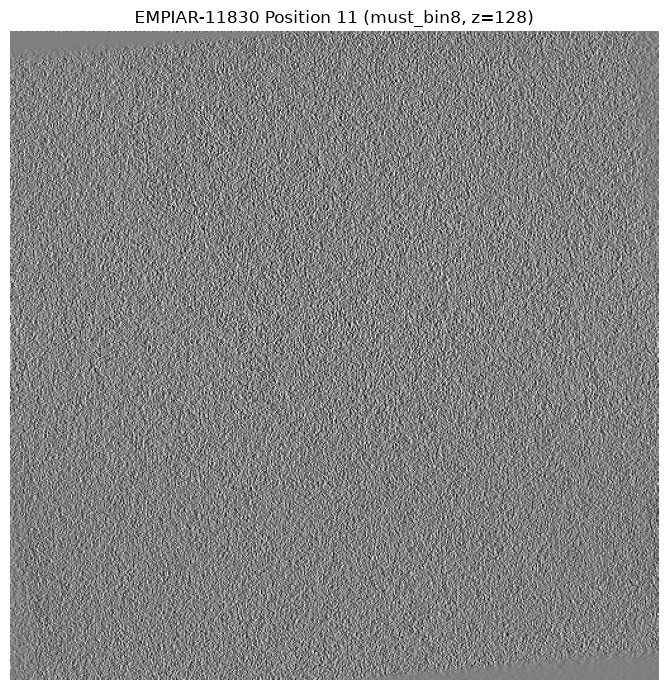

In [5]:
lo, hi = np.percentile(img, [1, 99])
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(img, cmap="gray", vmin=lo, vmax=hi)
ax.set_title(f"EMPIAR-11830 Position 11 (must_bin8, z={z_mid})")
ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Scaling Analysis on AWS and POSIX Workflows

1. **Compute placement:** `s3://subspatial-opendata` is hosted in **`eu-north-1` (Stockholm)**. Launching EC2 or AWS Batch instances in `eu-north-1` provides high-throughput, same-region S3 reads.
2. **Fast bulk staging:** For workflows reading full volumes to local NVMe scratch, [`s5cmd`](https://github.com/peak/s5cmd) saturates network links cleanly:
   ```bash
   s5cmd --no-sign-request cp "s3://subspatial-opendata/empiar-mirror/empiar-11830/data/must_bin8/*Position_11*" ./local_scratch/
   ```
3. **POSIX access for legacy cryo-ET tools (IMOD, RELION, TOMOMAN):** On Linux EC2 or HPC nodes, mount the bucket directly with [`mountpoint-s3`](https://github.com/awslabs/mountpoint-s3) without managing any intermediary file servers:
   ```bash
   mount-s3 --no-sign-request --region eu-north-1 --cache /tmp/s3-cache subspatial-opendata /mnt/subspatial-opendata
   ```
4. **Documentation and issue tracking:** Browse dataset documentation or report issues in [subspatial-org/open-data](https://github.com/subspatial-org/open-data).

## 5. Community Challenges and Next Steps

- **Automated cellular segmentation:** Compare segmentation models across `must_bin8` (fast exploration) and `cryocare_bin4` (denoised higher resolution) volumes for membranes, ribosomes, and cytoskeletal structures.
- **Streaming ML dataloaders:** Build PyTorch or Dask training pipelines that sample 3D subvolumes directly from `s3://subspatial-opendata` using HTTP `Range` reads in `eu-north-1` without pre-copying the full multi-terabyte corpus.
- **Cross-denoising benchmarks:** Quantify particle-picking precision and recall differences between `must_bin4`, `cryocare_bin4`, and `ctf3d_bin4` reconstructions on matched positions.

Subscribe an Amazon SQS queue or AWS Lambda function to `arn:aws:sns:eu-north-1:732227445052:subspatial-opendata-notifications` to receive notifications whenever new dataset release manifests are published.